In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
d=pd.read_csv("/content/diabetesdata.csv")

In [ ]:
d.head(5)

,Age,Gender,Polyuria,Polydipsia,sudden weight loss,weakness,Polyphagia,Genital thrush,visual blurring,Itching,Irritability,delayed healing,partial paresis,muscle stiffness,Alopecia,Obesity,class
0,40,Male,No,Yes,No,Yes,No,No,No,Yes,No,Yes,No,Yes,Yes,Yes,Positive
1,58,Male,No,No,No,Yes,No,No,Yes,No,No,No,Yes,No,Yes,No,Positive
2,41,Male,Yes,No,No,Yes,Yes,No,No,Yes,No,Yes,No,Yes,Yes,No,Positive
3,45,Male,No,No,Yes,Yes,Yes,Yes,No,Yes,No,Yes,No,No,No,No,Positive
4,60,Male,Yes,Yes,Yes,Yes,Yes,No,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Positive


In [ ]:
1. #shape of the data
d.shape

(520, 17)

In [ ]:
2. #info
d.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 520 entries, 0 to 519
Data columns (total 17 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   Age                 520 non-null    int64 
 1   Gender              520 non-null    object
 2   Polyuria            520 non-null    object
 3   Polydipsia          520 non-null    object
 4   sudden weight loss  520 non-null    object
 5   weakness            520 non-null    object
 6   Polyphagia          520 non-null    object
 7   Genital thrush      520 non-null    object
 8   visual blurring     520 non-null    object
 9   Itching             520 non-null    object
 10  Irritability        520 non-null    object
 11  delayed healing     520 non-null    object
 12  partial paresis     520 non-null    object
 13  muscle stiffness    520 non-null    object
 14  Alopecia            520 non-null    object
 15  Obesity             520 non-null    object
 16  class               520 no

In [ ]:
3. #null value
d.isnull().sum()

,0
Age,0
Gender,0
Polyuria,0
Polydipsia,0
sudden weight loss,0
weakness,0
Polyphagia,0
Genital thrush,0
visual blurring,0
Itching,0


In [ ]:
4. #duplicate
d.duplicated().sum()

np.int64(269)

**EDA**

In [ ]:
#univariate anal

d

,Age,Gender,Polyuria,Polydipsia,sudden weight loss,weakness,Polyphagia,Genital thrush,visual blurring,Itching,Irritability,delayed healing,partial paresis,muscle stiffness,Alopecia,Obesity,class
0,40,Male,No,Yes,No,Yes,No,No,No,Yes,No,Yes,No,Yes,Yes,Yes,Positive
1,58,Male,No,No,No,Yes,No,No,Yes,No,No,No,Yes,No,Yes,No,Positive
2,41,Male,Yes,No,No,Yes,Yes,No,No,Yes,No,Yes,No,Yes,Yes,No,Positive
3,45,Male,No,No,Yes,Yes,Yes,Yes,No,Yes,No,Yes,No,No,No,No,Positive
4,60,Male,Yes,Yes,Yes,Yes,Yes,No,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Positive
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
515,39,Female,Yes,Yes,Yes,No,Yes,No,No,Yes,No,Yes,Yes,No,No,No,Positive
516,48,Female,Yes,Yes,Yes,Yes,Yes,No,No,Yes,Yes,Yes,Yes,No,No,No,Positive
517,58,Female,Yes,Yes,Yes,Yes,Yes,No,Yes,No,No,No,Yes,Yes,No,Yes,Positive
518,32,Female,No,No,No,Yes,No,No,Yes,Yes,No,Yes,No,No,Yes,No,Negative


<function matplotlib.pyplot.show(close=None, block=None)>

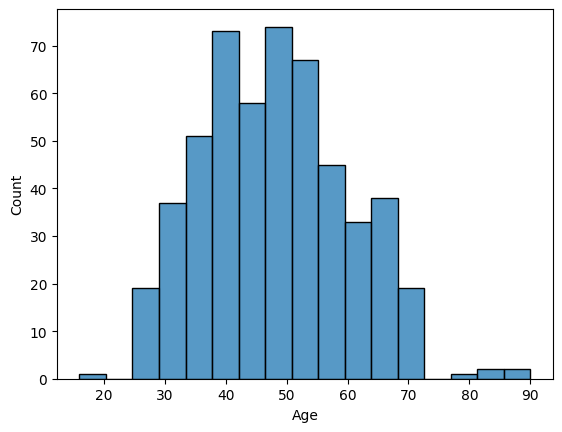

In [ ]:
sns.histplot(d['Age'])
plt.show

/tmp/ipykernel_13052/2906643281.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(d['Age'])


<function matplotlib.pyplot.show(close=None, block=None)>

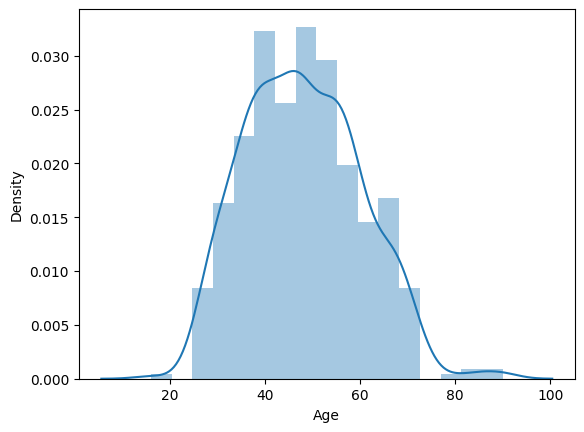

In [ ]:
#prob dist
sns.distplot(d['Age'])
plt.show

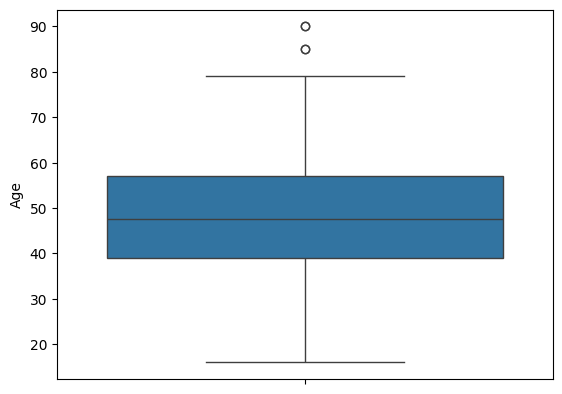

In [ ]:
sns.boxplot(d['Age'])
plt.show()

In [ ]:
#categorical univ
categorical=['Gender','Polyuria','Polydipsia','sudden weight loss','weakness','Polyphagia','Genital thrush','visual blurring','Itching','Irritability','delayed healing','partial paresis','muscle stiffness','Alopecia','Obesity']
len(categorical)

15

<function matplotlib.pyplot.show(close=None, block=None)>

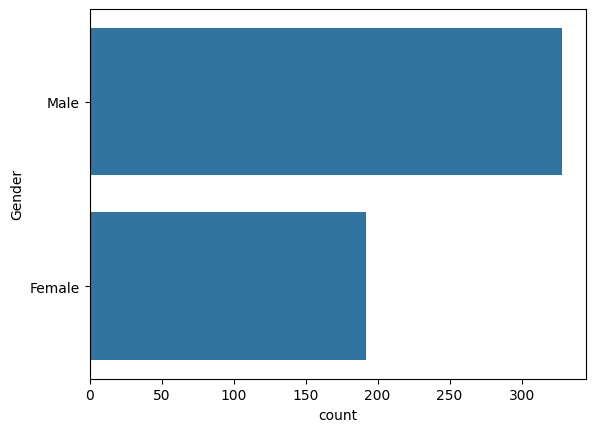

In [ ]:
# categorical
sns.countplot(d['Gender'])
plt.show

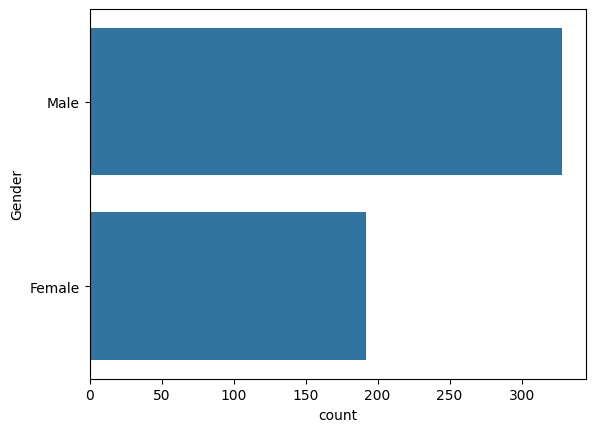

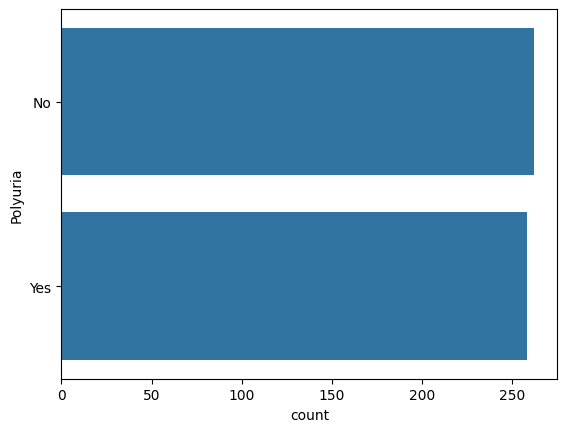

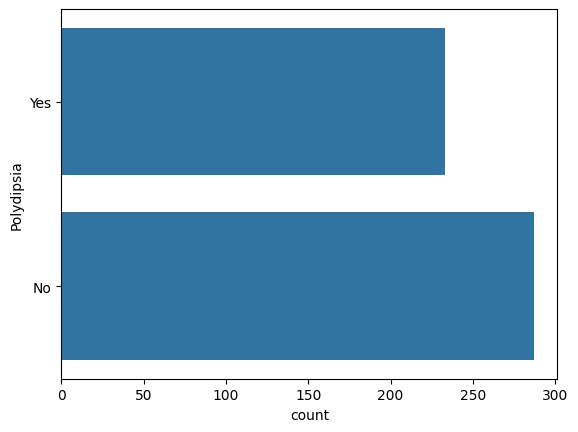

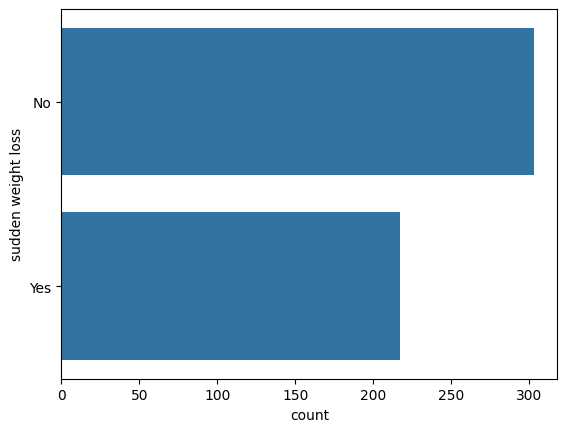

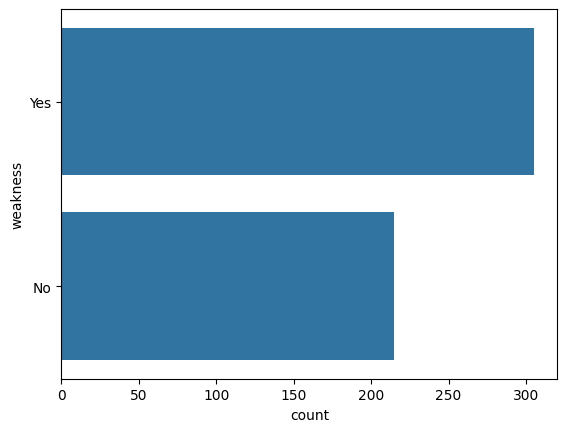

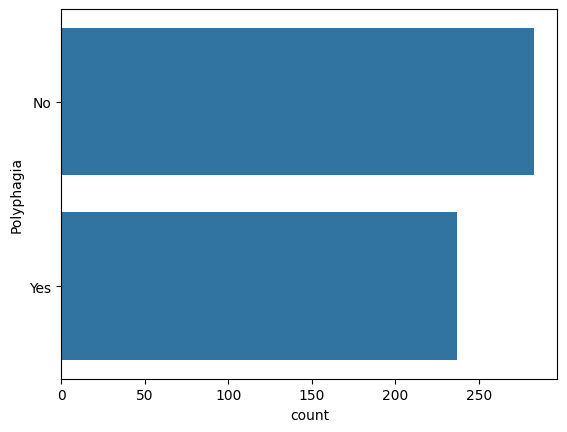

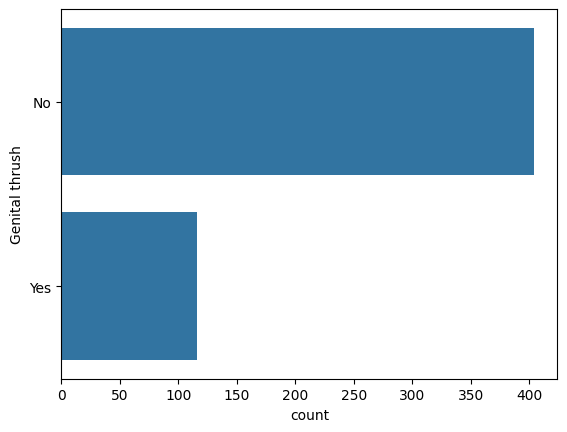

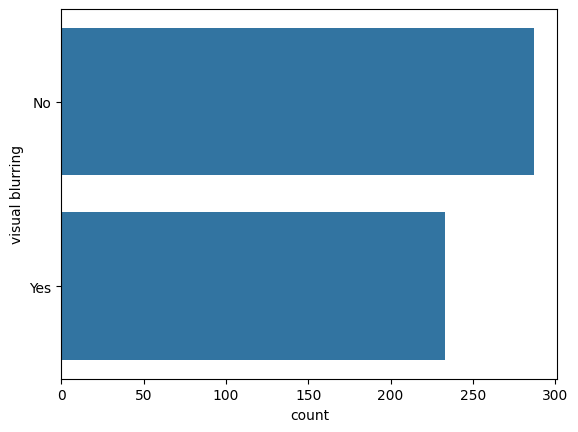

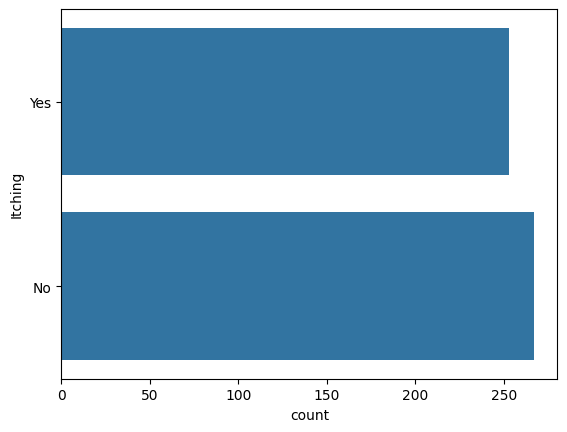

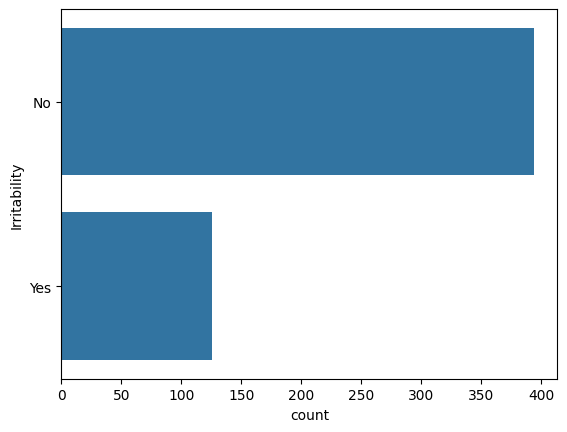

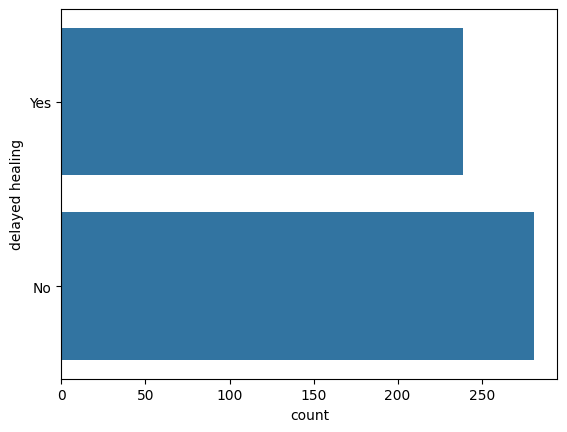

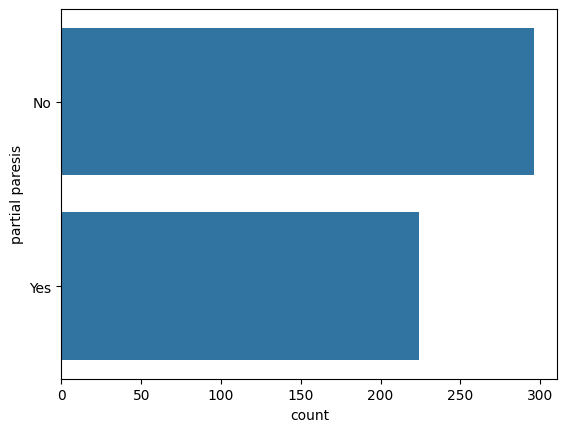

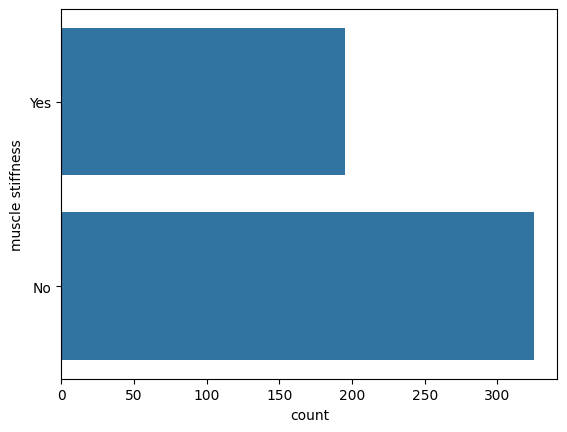

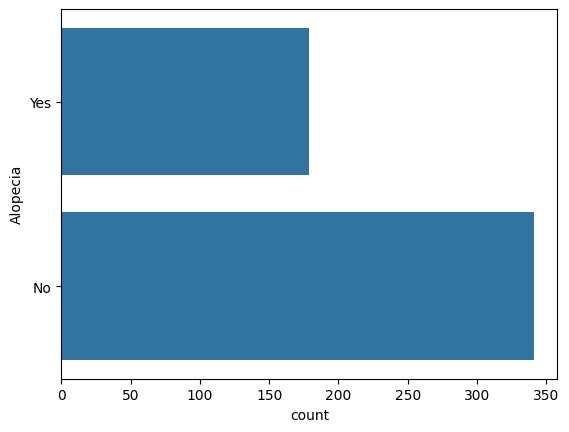

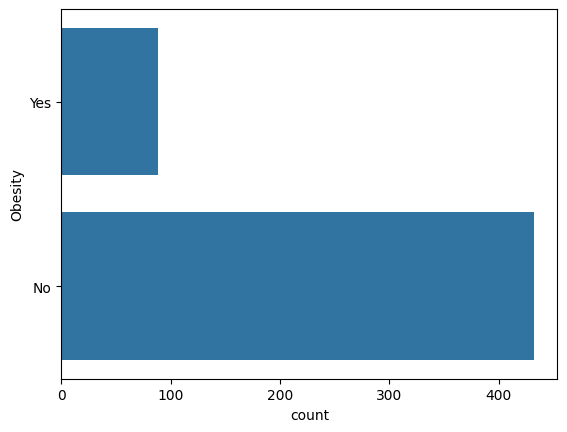

In [ ]:
for i in categorical:
  sns.countplot(d[i])
  plt.show()

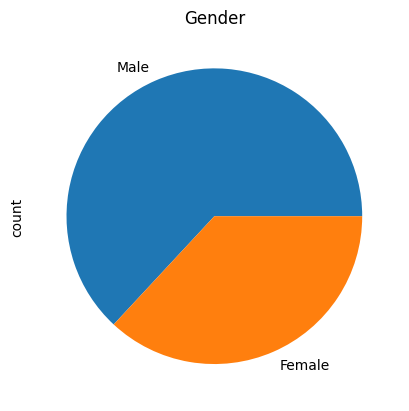

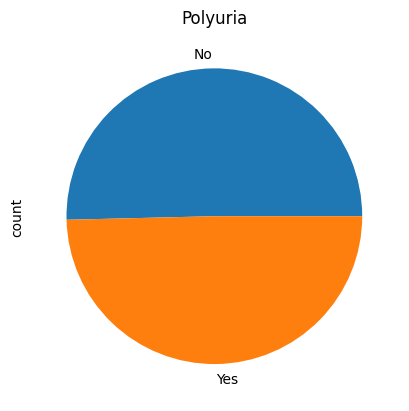

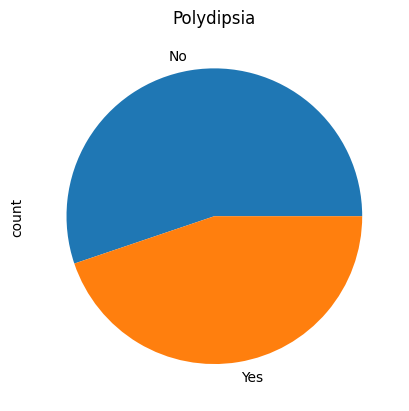

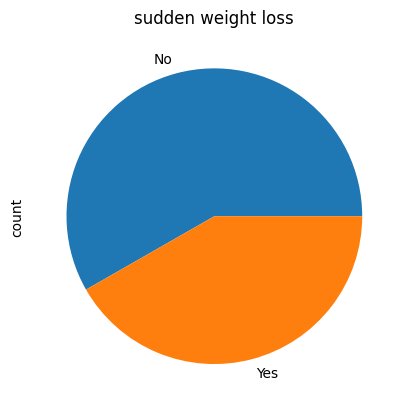

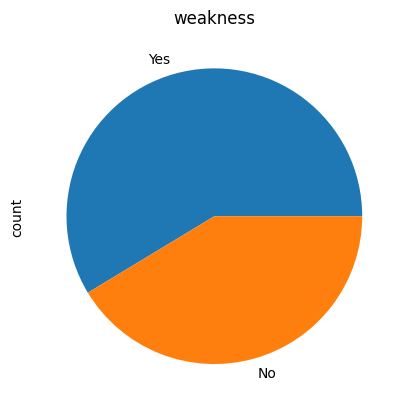

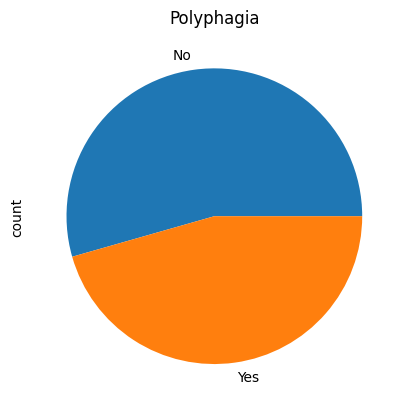

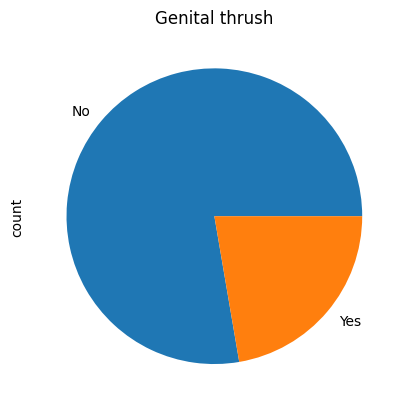

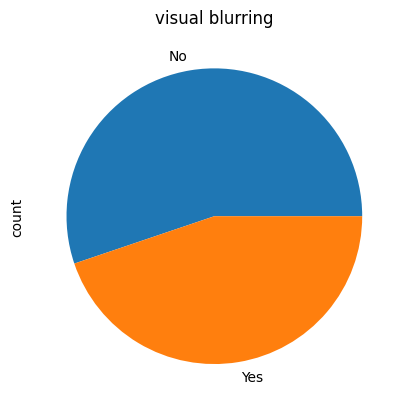

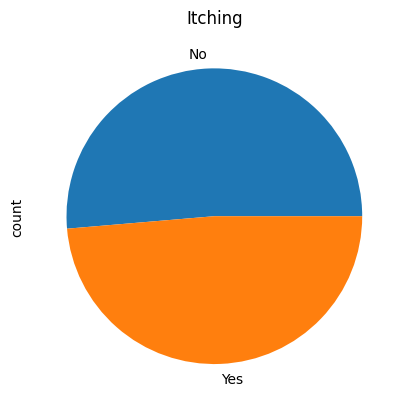

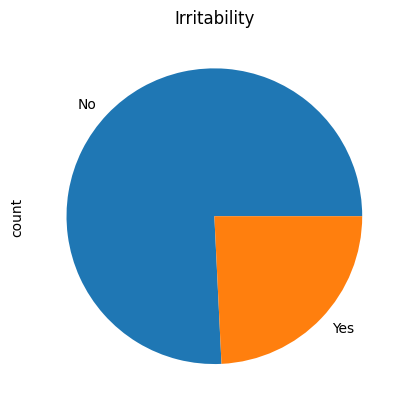

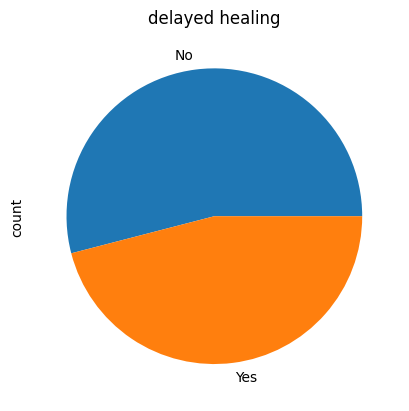

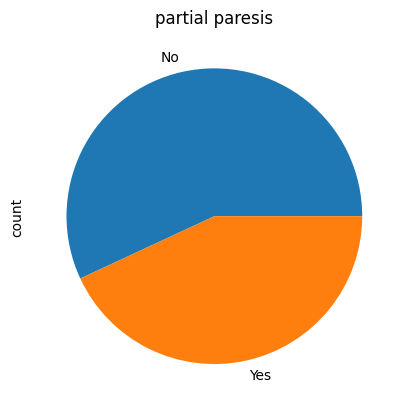

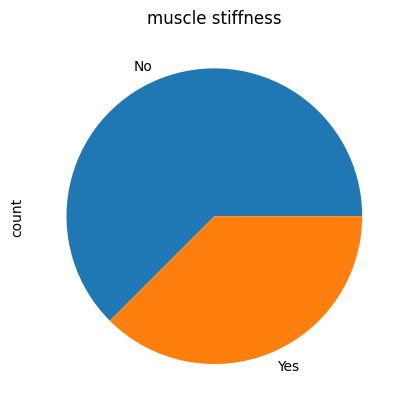

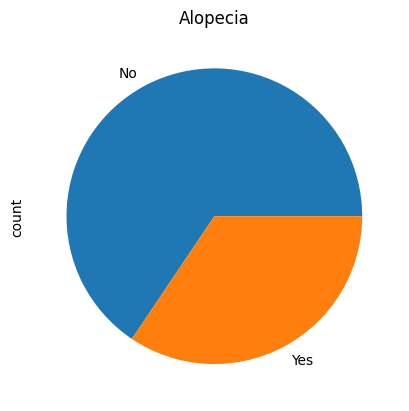

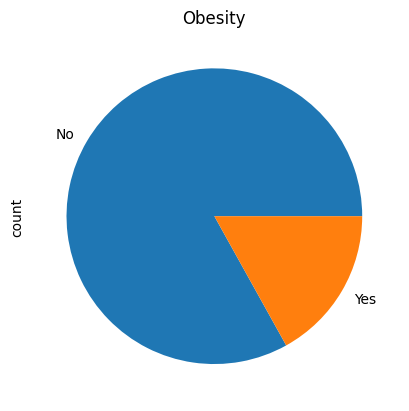

In [ ]:
for i in categorical:
  d[i].value_counts().plot(kind='pie')
  plt.title(i)
  plt.show()

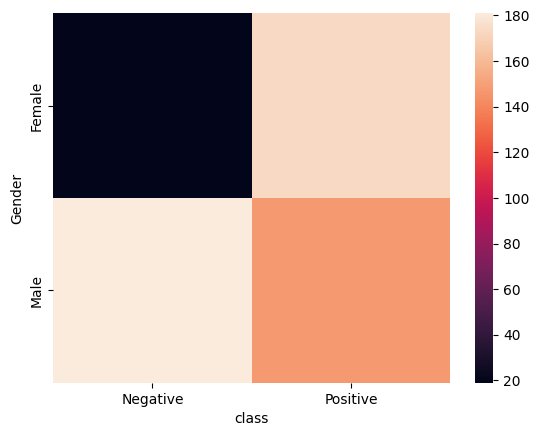

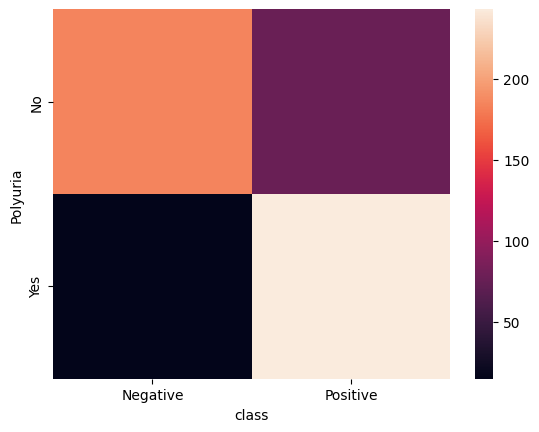

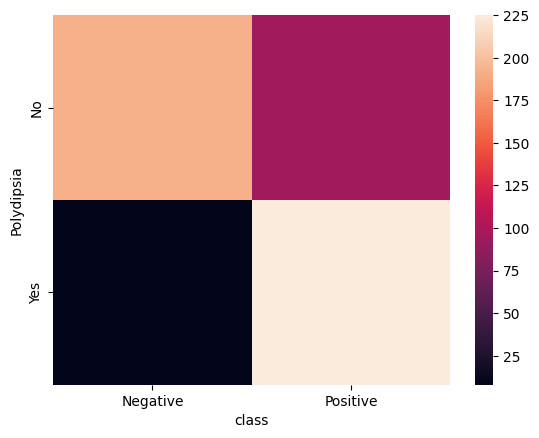

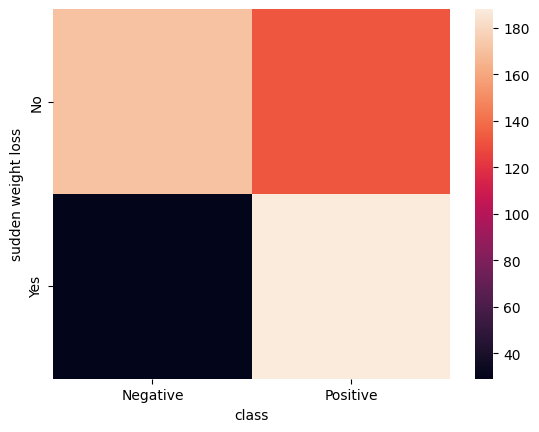

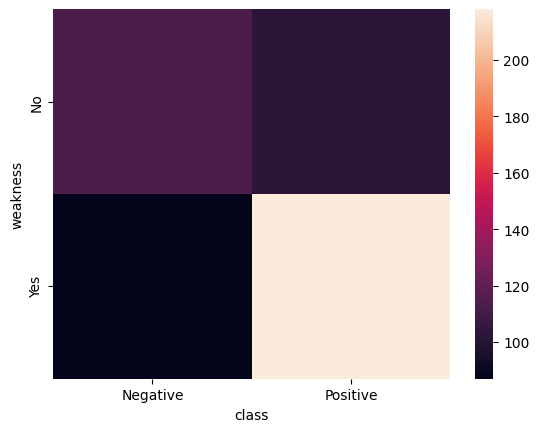

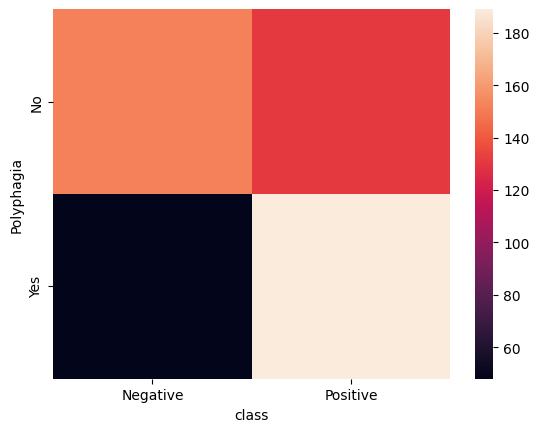

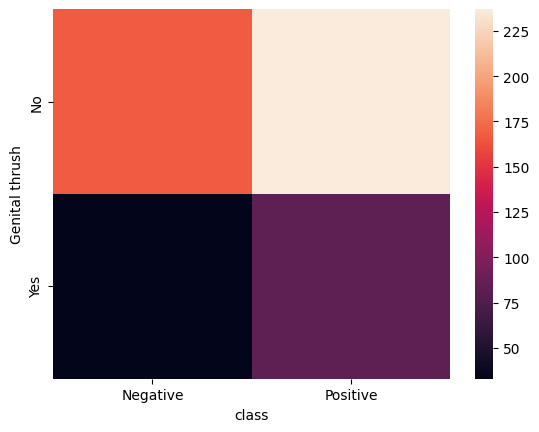

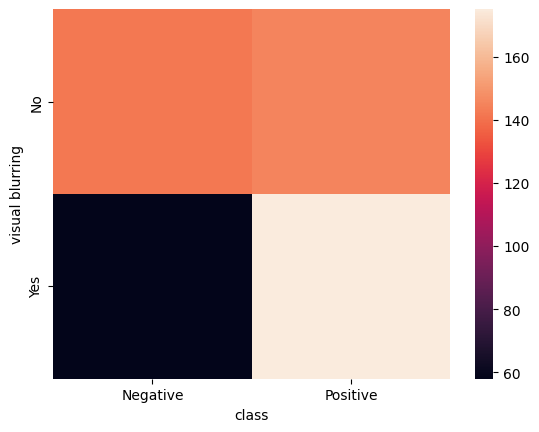

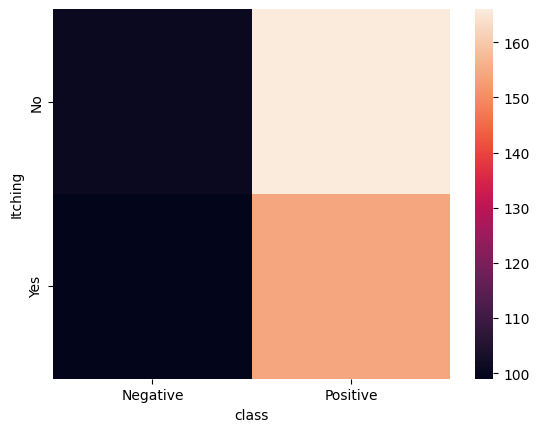

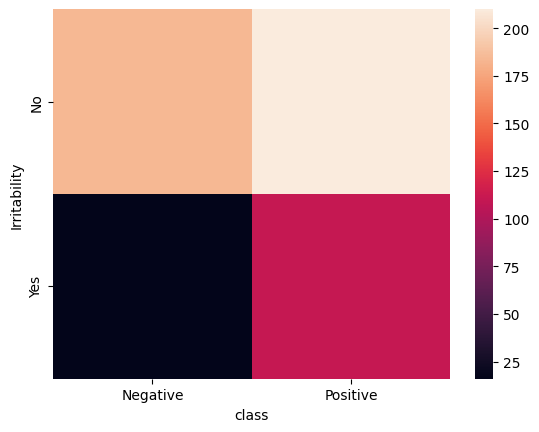

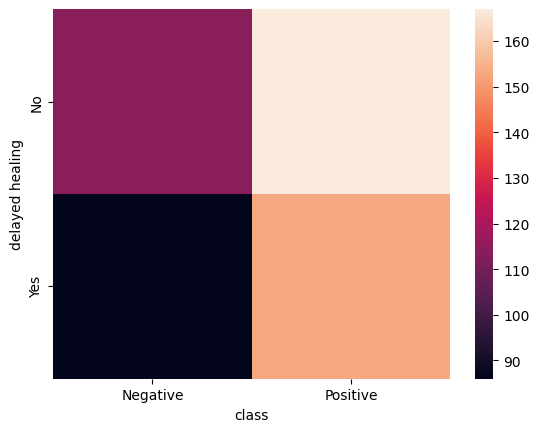

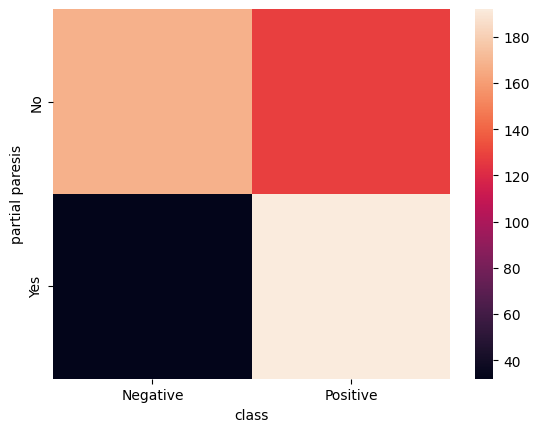

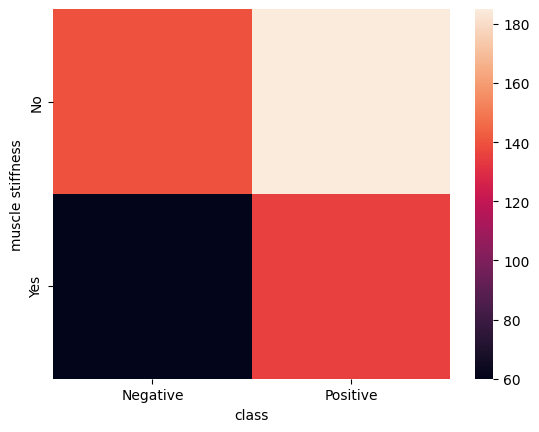

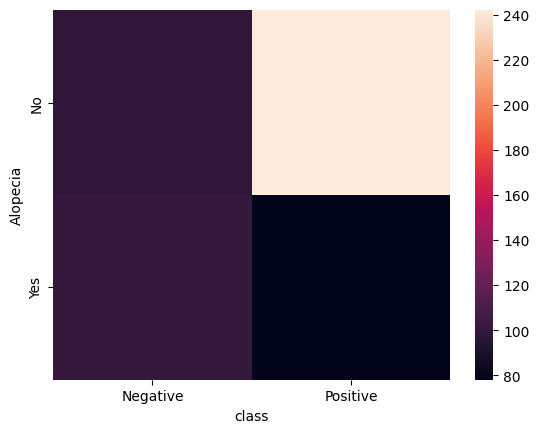

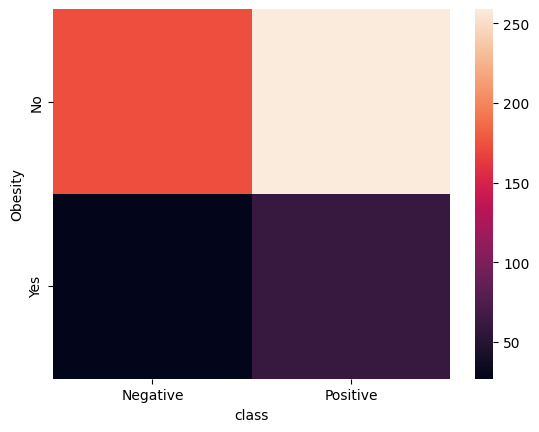

In [ ]:
#heatmap
for i in categorical:
  sns.heatmap(pd.crosstab(d[i],d['class']))
  plt.show()

**Preprocessing**

In [ ]:
d=d.drop_duplicates()

In [ ]:
d.shape

(251, 17)

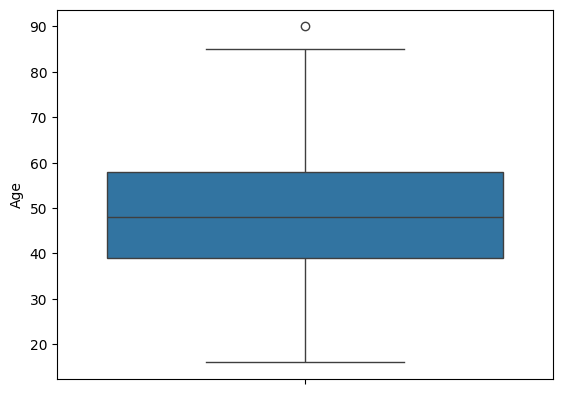

In [ ]:
sns.boxplot(d['Age'])
plt.show()

In [ ]:
Q1 = d['Age'].quantile(0.25)
Q3 = d['Age'].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

d = d[(d['Age'] >= lower) & (d['Age'] <= upper)]

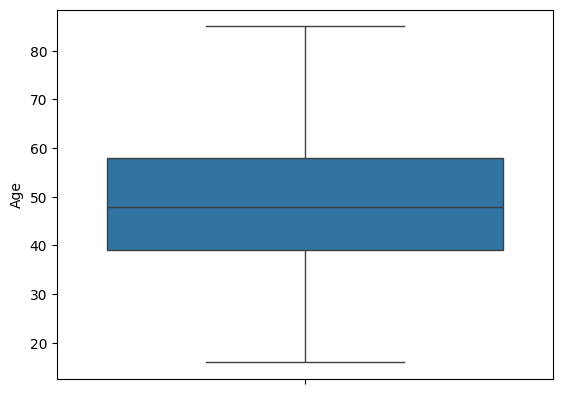

In [ ]:
sns.boxplot(d['Age'])
plt.show()

**Normalization/Scaling**

In [ ]:
x=d.drop('class', axis=1)
y=d['class']

In [ ]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [ ]:
x_train

,Age,Gender,Polyuria,Polydipsia,sudden weight loss,weakness,Polyphagia,Genital thrush,visual blurring,Itching,Irritability,delayed healing,partial paresis,muscle stiffness,Alopecia,Obesity
134,35,Male,Yes,Yes,Yes,Yes,No,No,No,No,No,No,No,No,No,No
327,47,Male,No,No,No,No,No,No,No,No,Yes,No,Yes,No,No,Yes
508,58,Male,No,No,No,Yes,No,No,No,Yes,No,Yes,No,Yes,Yes,No
121,35,Male,Yes,Yes,No,Yes,Yes,Yes,No,Yes,No,Yes,Yes,Yes,No,No
138,51,Male,Yes,Yes,Yes,Yes,No,Yes,No,No,Yes,Yes,Yes,No,Yes,No
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
108,25,Male,Yes,Yes,No,No,Yes,Yes,Yes,Yes,No,Yes,No,No,Yes,No
14,60,Male,Yes,Yes,No,Yes,Yes,No,Yes,Yes,No,Yes,Yes,No,No,No
93,40,Female,Yes,Yes,No,Yes,Yes,No,No,Yes,No,No,Yes,No,No,No
213,49,Male,No,Yes,No,No,No,No,No,Yes,No,No,Yes,No,No,Yes


In [ ]:
from sklearn.preprocessing import OneHotEncoder,StandardScaler,LabelEncoder


In [ ]:
from sklearn.compose import make_column_transformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
import pandas as pd # Ensure pandas is imported if not already

# Convert x_train and x_test back to DataFrames as ColumnTransformer expects them
# when using string column names.
x_train = pd.DataFrame(x_train, columns=x.columns)
x_test = pd.DataFrame(x_test, columns=x.columns)

ct=make_column_transformer(
    (OneHotEncoder(drop="first"),categorical),
    (StandardScaler(),['Age']),
)

x_train=ct.fit_transform(x_train)
x_test=ct.transform(x_test)

ValueError: Specifying the columns using strings is only supported for dataframes.

In [ ]:
x_train

array([[ 1.00000000e+00,  1.00000000e+00,  1.00000000e+00, ...,
         0.00000000e+00,  0.00000000e+00, -1.16558611e+00],
       [ 1.00000000e+00,  0.00000000e+00,  0.00000000e+00, ...,
         0.00000000e+00,  1.00000000e+00, -1.67937514e-01],
       [ 1.00000000e+00,  0.00000000e+00,  0.00000000e+00, ...,
         1.00000000e+00,  0.00000000e+00,  7.46573700e-01],
       ...,
       [ 0.00000000e+00,  1.00000000e+00,  1.00000000e+00, ...,
         0.00000000e+00,  0.00000000e+00, -7.49899196e-01],
       [ 1.00000000e+00,  0.00000000e+00,  1.00000000e+00, ...,
         0.00000000e+00,  1.00000000e+00, -1.66274766e-03],
       [ 1.00000000e+00,  1.00000000e+00,  0.00000000e+00, ...,
         1.00000000e+00,  0.00000000e+00,  1.74422230e+00]])

In [ ]:
print(type(x_train))

<class 'numpy.ndarray'>


In [ ]:
L=LabelEncoder()
y_train=L.fit_transform(y_train)
y_test=L.transform(y_test)

In [ ]:
y_train

array([1, 0, 0, 1, 1, 1, 0, 1, 0, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0, 0, 1, 1,
       1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1,
       1, 0, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1,
       1, 1, 1, 0, 1, 1, 1, 1, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1,
       1, 0, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1, 0, 1,
       0, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0, 1, 0, 1, 0, 0, 1, 1, 1,
       1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 1, 1, 1, 0, 1, 0, 0, 0, 1, 1, 1,
       0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 1, 1, 1,
       0, 1])

In [ ]:
from sklearn.ensemble import RandomForestClassifier

In [ ]:
M=RandomForestClassifier()
M.fit(x_train,y_train)

RandomForestClassifier()

In [ ]:
from sklearn.metrics import accuracy_score
y_pred=M.predict(x_test)
accuracy_score(y_test,y_pred)


0.92